## 📓 Notebook 02: Missing Data Imputation

**Skills practiced:** `SimpleImputer` (mean, median, most_frequent), comparing distributions before and after, fitting on train only.

**Goal:** Compare mean vs. median imputation on a numeric column, choose a strategy for a categorical column, and justify each choice.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer

In [23]:
X_train=pd.read_csv('../data/processed/stage_1/x_train.csv')

In [24]:
X_train.isna().sum()

t1              0
t2              0
hum             0
wind_speed      0
weather_code    0
is_holiday      0
is_weekend      0
season          0
hour            0
dtype: int64

ARTIFICIALLY introducing NaN values for practice: randomly setted 5% of the 'hum' column to NaN 

In [25]:
X_train.loc[X_train.sample(frac=0.1).index, 'hum'] = np.nan

In [26]:
imp = SimpleImputer(strategy='mean')
imp.fit(X_train)

X_train_imp = pd.DataFrame(imp.transform(X_train), columns=X_train.columns, index=X_train.index)

In [27]:
imp2=SimpleImputer(strategy='median')
imp2.fit(X_train)

X_train_imp2 = pd.DataFrame(imp2.transform(X_train), columns=X_train.columns, index=X_train.index)

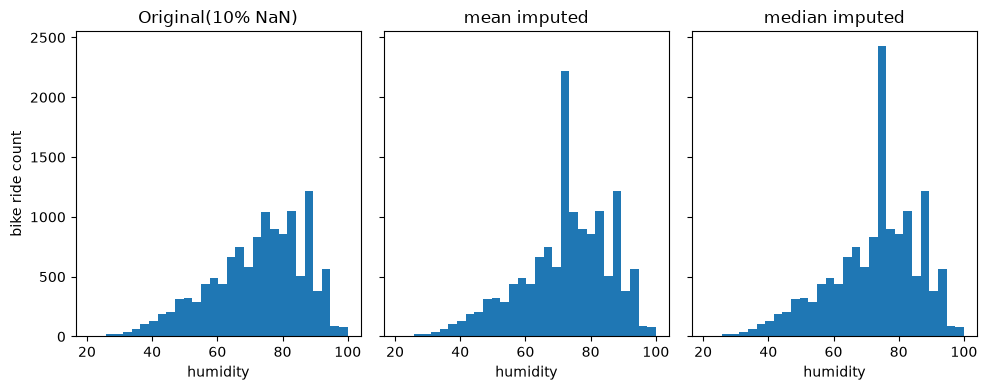

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharex=True, sharey=True)

axes[0].hist(X_train['hum'], bins=30)
axes[0].set_title('Original(10% NaN)')
axes[0].set_xlabel('humidity')
axes[0].set_ylabel('bike ride count')

axes[1].hist(X_train_imp['hum'], bins=30)
axes[1].set_title('mean imputed')
axes[1].set_xlabel('humidity')

axes[2].hist(X_train_imp2['hum'], bins=30)
axes[2].set_title('median imputed')
axes[2].set_xlabel('humidity')

plt.tight_layout()
plt.show()